<a href="https://colab.research.google.com/github/h8naf1/FSD_Tugas-Kelompok-Linear-Regression-dan-Logistic-Regression-/blob/main/B_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAGIAN B: LOGISTIC REGRESSION — KLASIFIKASI SMS SPAM DETECTION

## B1. Deskripsi Dataset
- **Sumber Dataset**: Kaggle / UCI Machine Learning Repository (SMS Spam Collection Dataset)
- **Tautan Dataset**: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset
- **Jumlah Baris & Kolom**: ~5,572 baris dan 2 kolom utama (`v1`/`label` dan `v2`/`text`)
- **Variabel Target**: `label` (Kategorikal Biner):
  - `ham` (0): Pesan biasa / wajar
  - `spam` (1): Pesan penipuan / promosi berbahaya
- **Fitur Prediktor**:
  - `text`: Isikandungan pesan SMS yang dikirimkan.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_curve, auc

# 1. Memuat dataset (sesuaikan nama file jika 'spam.csv' atau 'SMSSpamCollection')
try:
    df = pd.read_csv('spam.csv', encoding='latin-1')
    df = df[['v1', 'v2']]
    df.columns = ['label', 'text']
except:
    df = pd.read_csv('SMSSpamCollection', sep='\t', names=['label', 'text'])

print(f"Jumlah baris: {df.shape[0]}, Jumlah kolom: {df.shape[1]}")
df.head()

Jumlah baris: 5572, Jumlah kolom: 2


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## B2. Eksplorasi dan Visualisasi Data (EDA)
Di bawah ini dilakukan visualisasi untuk memahami karakteristik data SMS:
1. **Bar Chart Distribusi Kelas Target**: Memeriksa apakah terdapat ketidakseimbangan kelas (*class imbalance*).
2. **Box Plot Panjang Pesan per Kelas**: Membandingkan panjang karakter SMS antara pesan *ham* dan *spam*.
3. **Histogram Distribusi Jumlah Kata**: Melihat pola jumlah kata pada kedua kategori pesan.

/tmp/ipykernel_892/3660949905.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='Set2')
/tmp/ipykernel_892/3660949905.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='label', y='char_length', palette='Set2')


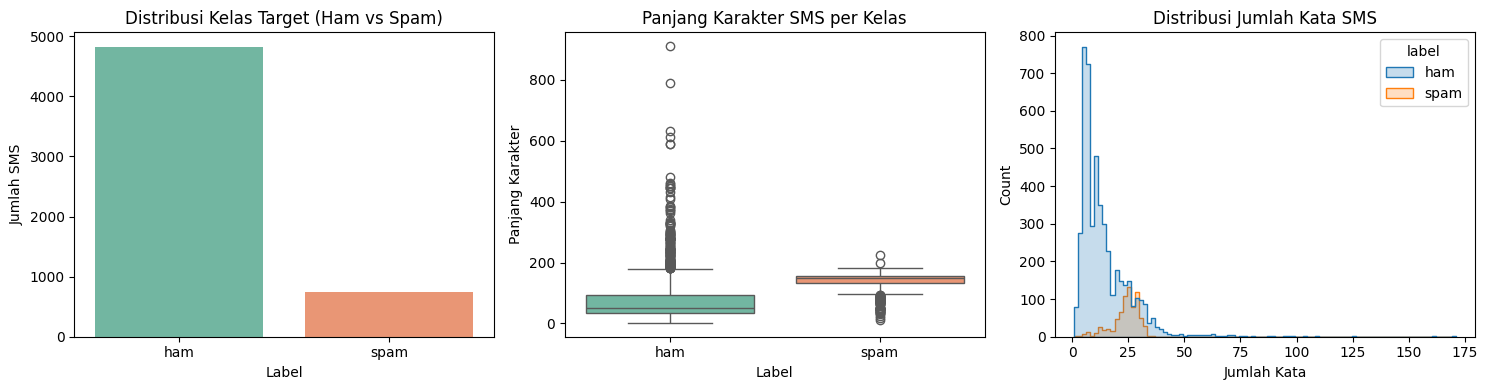

In [2]:
# Rekayasa Fitur Sederhana untuk EDA
df['char_length'] = df['text'].astype(str).apply(len)
df['word_count'] = df['text'].astype(str).apply(lambda x: len(x.split()))

plt.figure(figsize=(15, 4))

# 1. Bar Chart Distribusi Kelas
plt.subplot(1, 3, 1)
sns.countplot(data=df, x='label', palette='Set2')
plt.title('Distribusi Kelas Target (Ham vs Spam)')
plt.xlabel('Label')
plt.ylabel('Jumlah SMS')

# 2. Box Plot Panjang Karakter per Kelas
plt.subplot(1, 3, 2)
sns.boxplot(data=df, x='label', y='char_length', palette='Set2')
plt.title('Panjang Karakter SMS per Kelas')
plt.xlabel('Label')
plt.ylabel('Panjang Karakter')

# 3. Histogram Jumlah Kata
plt.subplot(1, 3, 3)
sns.histplot(data=df, x='word_count', hue='label', element='step', common_norm=False)
plt.title('Distribusi Jumlah Kata SMS')
plt.xlabel('Jumlah Kata')

plt.tight_layout()
plt.show()

### Temuan EDA:
1. **Ketidakseimbangan Kelas (*Class Imbalance*)**: Sebagian besar pesan berkategori `ham` (~86%), sedangkan `spam` hanya berkisar ~14%.
2. **Panjang Pesan**: Pesan `spam` cenderung secara signifikan lebih panjang (memiliki karakter dan jumlah kata lebih banyak) dibandingkan pesan `ham`.

## B3. Preprocessing Data & B4. Pemilihan Fitur
Langkah pembersihan dan ekstraksi data:
1. Mengubah label `ham` menjadi `0` dan `spam` menjadi `1`.
2. Membersihkan data kosong (*missing values*) dan duplikat.
3. Menggunakan **TF-IDF Vectorizer** (`max_features=1000`) untuk mengubah teks SMS menjadi fitur numerik matriks kata.
4. Menangani *class imbalance* pada pemodelan dengan opsi `class_weight='balanced'`.

In [3]:
# Encoding Target
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# Hapus duplikat & missing values
df_clean = df.drop_duplicates().dropna(subset=['text', 'target'])

# Ekstraksi Fitur Teks menggunakan TF-IDF
tfidf = TfidfVectorizer(max_features=1000, stop_words='english')
X = tfidf.fit_transform(df_clean['text']).toarray()
y = df_clean['target']

print(f"Ukuran Matriks Fitur (X): {X.shape}")

Ukuran Matriks Fitur (X): (5169, 1000)


## B5. Pembagian Data (Stratified Split)
Data dibagi menjadi **80% Data Latih** dan **20% Data Uji**.
Wajib menggunakan parameter `stratify=y` agar rasio antara `ham` (0) dan `spam` (1) pada data latih dan data uji tetap terjaga secara seimbang.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Ukuran Data Latih: {X_train.shape[0]} baris")
print(f"Ukuran Data Uji  : {X_test.shape[0]} baris")

Ukuran Data Latih: 4135 baris
Ukuran Data Uji  : 1034 baris


## B6. Pemodelan Logistic Regression
Model dibangun menggunakan `LogisticRegression` dengan penambahan `class_weight='balanced'` untuk menangani ketidakseimbangan kelas pesan spam.

In [5]:
model_log = LogisticRegression(class_weight='balanced', random_state=42)
model_log.fit(X_train, y_train)

# Menampilkan kata-kata (fitur) dengan koefisien tertinggi berpengaruh ke Spam
feature_names = np.array(tfidf.get_feature_names_out())
sorted_coef_index = model_log.coef_[0].argsort()

print("10 Kata Teratas Indikator SPAM (Koefisien Positif Tertinggi):")
for idx in sorted_coef_index[-10:][::-1]:
    print(f"- {feature_names[idx]}: {model_log.coef_[0][idx]:.4f}")

10 Kata Teratas Indikator SPAM (Koefisien Positif Tertinggi):
- txt: 4.4073
- mobile: 3.9552
- uk: 3.7407
- reply: 3.5621
- 50: 3.4911
- claim: 3.4668
- www: 3.4660
- text: 3.3049
- 150p: 3.2659
- free: 3.2507


## B7. Evaluasi Model
Menghitung Accuracy, Precision, Recall, dan F1-Score serta menampilkan Confusion Matrix dan Kurva ROC-AUC.

--- METRIK EVALUASI LOGISTIC REGRESSION ---
Accuracy  : 0.9758
Precision : 0.9141
Recall    : 0.8931
F1-Score  : 0.9035


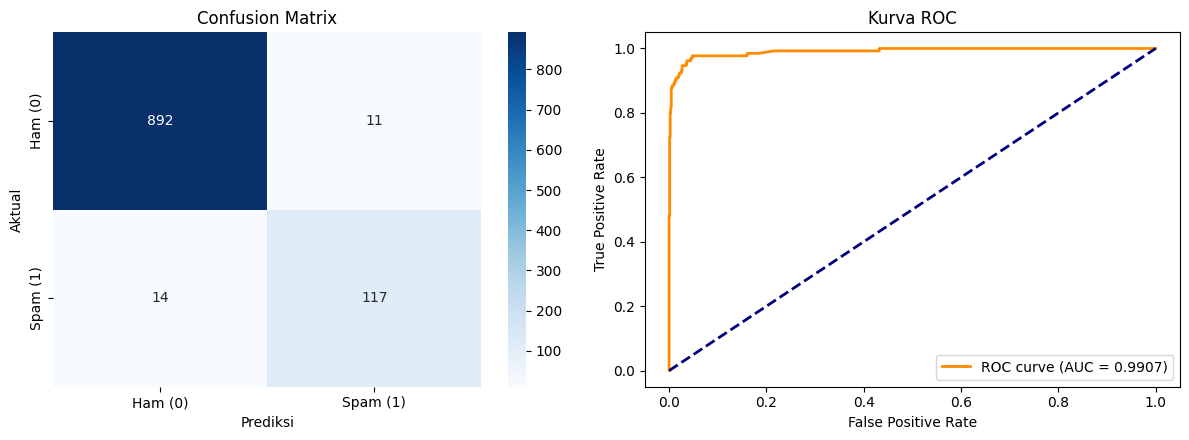

In [6]:
# Prediksi
y_pred = model_log.predict(X_test)
y_prob = model_log.predict_proba(X_test)[:, 1]

# Hitung Metrik
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("--- METRIK EVALUASI LOGISTIC REGRESSION ---")
print(f"Accuracy  : {acc:.4f}")
print(f"Precision : {prec:.4f}")
print(f"Recall    : {rec:.4f}")
print(f"F1-Score  : {f1:.4f}")

# Plot Confusion Matrix & ROC Curve
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax[0],
            xticklabels=['Ham (0)', 'Spam (1)'], yticklabels=['Ham (0)', 'Spam (1)'])
ax[0].set_title('Confusion Matrix')
ax[0].set_xlabel('Prediksi')
ax[0].set_ylabel('Aktual')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
ax[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.4f})')
ax[1].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[1].set_title('Kurva ROC')
ax[1].set_xlabel('False Positive Rate')
ax[1].set_ylabel('True Positive Rate')
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

## B8. Analisis Performa Model
1. **Metrik Paling Relevan**: Pada kasus pendeteksian spam, metrik **Precision** dan **Recall** lebih relevan dibanding Accuracy.
   - High **Recall** memastikan bahwa sedapat mungkin tidak ada SMS spam penipuan yang lolos ke *inbox* pengguna.
   - High **Precision** memastikan pesan penting (`ham`) tidak salah terdeteksi sebagai spam.
2. **Evaluasi Kesalahan (Confusion Matrix)**: Penggunaan `class_weight='balanced'` terbukti efektif meningkatkan sensitivitas (Recall) model terhadap kelas minoritas (`spam`).
3. **Keterbatasan Model**: Logistic Regression bersifat linier, sehingga belum dapat memahami konteks kalimat secara kompleks atau kata-kata gaul/singkatan baru (*slang*) yang sering dimodifikasi oleh penipu.